# Neural network: a 1D-CNN that reads the last 30 flights

Same steps as `src/07_cnn.py`, with explanations. *(It trains about 15 networks and takes around 15 minutes.)*

So far every model looked at **one flight at a time**. Any sense of history came from clues we built by hand (like "change from own start"). A 1D-CNN instead looks at a **clip of the last 30 flights** and slides small stencils along it to spot shapes like a rise or a bend.

Two questions:
1. Can it match gradient boosting?
2. Does it still need our hand-made "change from own start" clues?

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from cmapss import (ENGINE_COLORS, WINDOW, add_baseline_features, apply_scaler, clip_rul,
                    feature_columns, fit_scaler, load_test_with_rul, load_train, make_cnn,
                    make_windows, plot_predicted_vs_true, predict_cnn, rmse, train_cnn)
N_START, SMOOTH, MAX_EPOCHS, SEEDS = 20, 10, 40, [0, 1, 2, 3, 4]
add_feats = lambda df: add_baseline_features(df, N_START, smooth=SMOOTH)
new_gb = lambda: GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0)

## Step 1: cut each engine into 30-flight clips

Clip 1 = flights 1-30, clip 2 = flights 2-31, and so on. Each clip's label is the RUL at its **last** flight, so a clip never contains the future.

Every column is also rescaled to a similar range (networks learn badly when one input is around 1,400 and another around 0.03). The rescaling numbers come from **training engines only**, so there is no peek at the test set.

In [2]:
train = add_feats(clip_rul(load_train()))
original = feature_columns(train)
chg = [c for c in train.columns if c.endswith('_chg')]
chg_smooth = [c for c in train.columns if c.endswith(f'_chg_avg{SMOOTH}')]
input_sets = {'CNN, 17 original': original,
              'CNN, + change from own start': original + chg + chg_smooth}
GB_COLS = original + chg + chg_smooth

X, y, units = make_windows(apply_scaler(train, original, fit_scaler(train, original)), original)
print('clips, flights per clip, columns per flight:', X.shape)
print('model size (numbers it learns):', sum(p.numel() for p in make_cnn(len(original)).parameters()))

clips, flights per clip, columns per flight: (17731, 30, 17)


model size (numbers it learns): 34753


## Step 2: five practice exams

Same as before: 80 engines to learn from, 20 held out, rotated five times. The network's error is recorded after every **epoch** (one pass through all the training clips), on the engines it studies and on the held-out ones.

The CNN cannot answer before an engine has 30 flights. To keep the comparison fair, gradient boosting is graded on **exactly the same flights**.

In [3]:
curves = {n: [] for n in input_sets}
train_curves = {n: [] for n in input_sets}
gb_scores = []
for k, (tr_idx, val_idx) in enumerate(GroupKFold(n_splits=5).split(train, groups=train['unit']), 1):
    tr, val = train.iloc[tr_idx], train.iloc[val_idx]
    for name, cols in input_sets.items():
        scaler = fit_scaler(tr, cols)
        Xtr, ytr, _ = make_windows(apply_scaler(tr, cols, scaler), cols)
        Xv, yv, _ = make_windows(apply_scaler(val, cols, scaler), cols)
        _, hist = train_cnn(Xtr, ytr, n_epochs=MAX_EPOCHS, seed=0, X_val=Xv, y_val=yv)
        curves[name].append([h['val'] for h in hist])
        train_curves[name].append([h['train'] for h in hist])
    gb = new_gb().fit(tr[GB_COLS], tr['RUL'])
    same = val[val['cycle'] >= WINDOW]
    gb_scores.append(rmse(same['RUL'], gb.predict(same[GB_COLS])))
    print(f'practice exam {k} done')

print(f"\n{'gradient boosting (best so far)':32s} {np.mean(gb_scores):.2f}")
best_epochs = {}
for name in input_sets:
    m = np.mean(curves[name], axis=0)
    best_epochs[name] = int(np.argmin(m)) + 1
    print(f'{name:32s} {m.min():.2f} at epoch {best_epochs[name]}  (at epoch {MAX_EPOCHS}: {m[-1]:.2f})')

practice exam 1 done


practice exam 2 done


practice exam 3 done


practice exam 4 done


practice exam 5 done

gradient boosting (best so far)  13.34
CNN, 17 original                 15.97 at epoch 5  (at epoch 40: 18.80)
CNN, + change from own start     15.20 at epoch 6  (at epoch 40: 16.35)


## Step 3: the learning curves

Blue = error on engines the network studied. Orange = error on held-out engines. If blue keeps falling while orange rises, the network is **overfitting** (memorizing practice questions instead of learning the subject). The dotted line marks the epoch with the lowest held-out error; we stop training there.

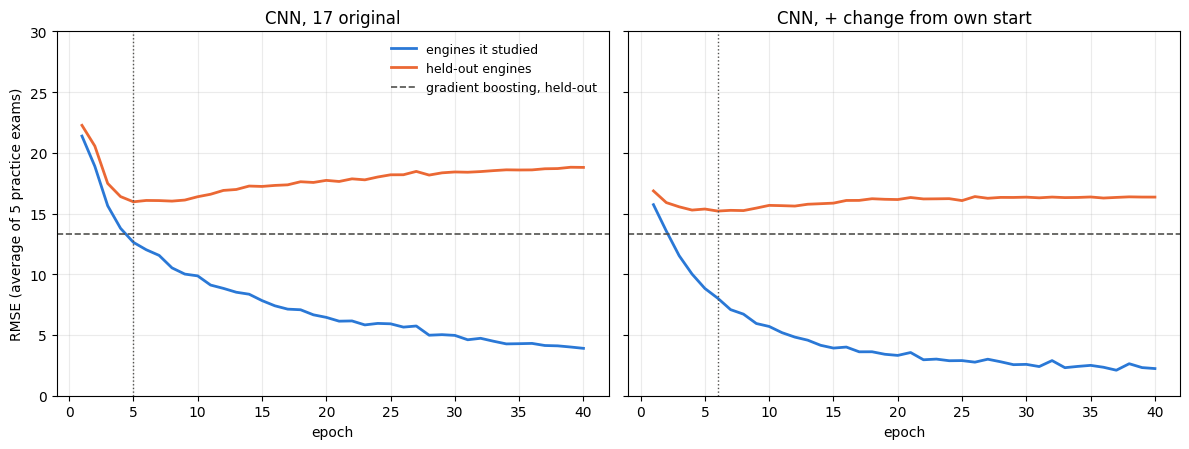

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
ep = np.arange(1, MAX_EPOCHS + 1)
for ax, name in zip(axes, input_sets):
    ax.plot(ep, np.mean(train_curves[name], axis=0), color=ENGINE_COLORS[0], lw=2, label='engines it studied')
    ax.plot(ep, np.mean(curves[name], axis=0), color=ENGINE_COLORS[1], lw=2, label='held-out engines')
    ax.axhline(np.mean(gb_scores), color='#52514e', ls='--', lw=1.2, label='gradient boosting, held-out')
    ax.axvline(best_epochs[name], color='#52514e', ls=':', lw=1)
    ax.set_title(name); ax.set_xlabel('epoch'); ax.grid(alpha=0.25)
axes[0].set_ylabel('RMSE (average of 5 practice exams)'); axes[0].set_ylim(0, 30)
axes[0].legend(frameon=False, fontsize=9)
plt.tight_layout()

## Step 4: the test set, once

The practice exams pick the inputs and the number of epochs. Then we train on all 100 training engines and grade on the last clip of each test engine.

A network starts from random numbers, so one run can be lucky or unlucky. We train **5 copies with different random starts (seeds)** and report the average and the range.

In [5]:
chosen = min(input_sets, key=lambda n: np.mean(curves[n], axis=0).min())
cols, n_epochs = input_sets[chosen], best_epochs[chosen]
print('chosen:', chosen, '|', n_epochs, 'epochs')
scaler = fit_scaler(train, cols)
Xtr, ytr, _ = make_windows(apply_scaler(train, cols, scaler), cols)
test = add_feats(load_test_with_rul())
Xte, yte, _ = make_windows(apply_scaler(test, cols, scaler), cols, last_only=True)
results = []
for seed in SEEDS:
    model, _ = train_cnn(Xtr, ytr, n_epochs=n_epochs, seed=seed)
    pred = np.clip(predict_cnn(model, Xte), 0, None)
    results.append((seed, rmse(yte, pred), int((pred > yte).sum()), pred))
    print(f'seed {seed}: test RMSE {results[-1][1]:.2f}, too high on {results[-1][2]}/100')
s = [r[1] for r in results]
print(f'average {np.mean(s):.2f}, range {min(s):.2f} to {max(s):.2f}')

chosen: CNN, + change from own start | 6 epochs


seed 0: test RMSE 16.63, too high on 40/100


seed 1: test RMSE 16.85, too high on 48/100


seed 2: test RMSE 17.80, too high on 52/100


seed 3: test RMSE 16.83, too high on 42/100


seed 4: test RMSE 17.04, too high on 45/100
average 17.03, range 16.63 to 17.80


gradient boosting (best so far): 15.18


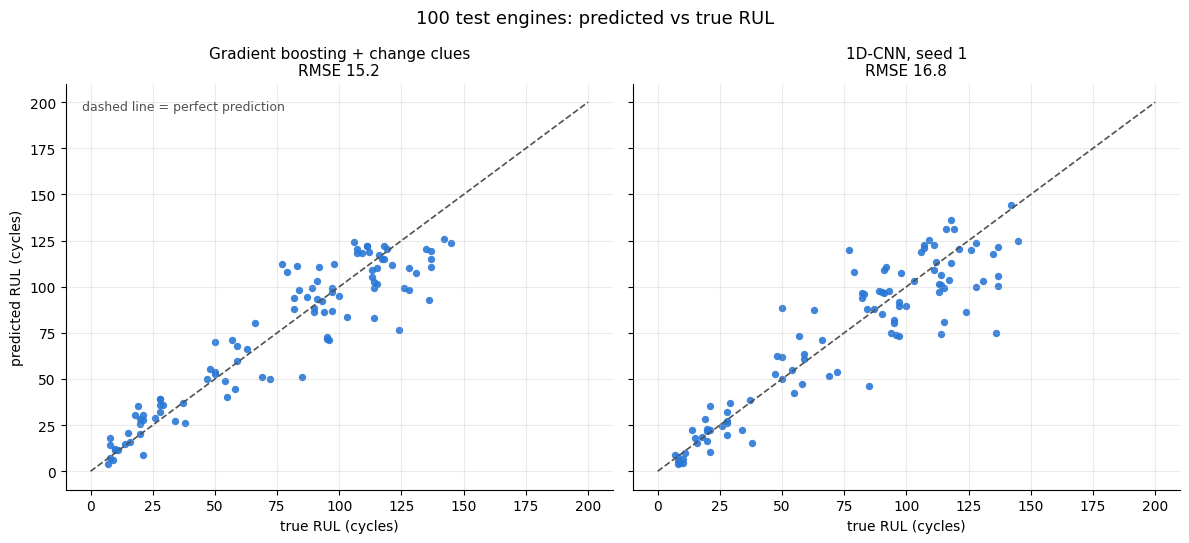

In [6]:
gb = new_gb().fit(train[GB_COLS], train['RUL'])
last = test.groupby('unit').tail(1)
gb_pred = gb.predict(last[GB_COLS])
print(f"gradient boosting (best so far): {rmse(last['RUL'], gb_pred):.2f}")
typical = sorted(results, key=lambda r: r[1])[len(results) // 2]
plot_predicted_vs_true([('Gradient boosting + change clues', last['RUL'].to_numpy(), gb_pred),
                        (f'1D-CNN, seed {typical[0]}', yte, typical[3])],
                       '100 test engines: predicted vs true RUL', limit=200);

## What we learned

- **The CNN did not beat gradient boosting.** Practice exams: 15.20 vs 13.34 (same flights). Test: 17.03 on average over 5 random starts (range 16.63 to 17.80) vs 15.18.
- **It overfits fast.** Error on studied engines keeps falling toward 2 to 4, but held-out error is lowest after only 5 or 6 epochs. With 100 training engines it starts memorizing them almost at once.
- **It still needs the hand-made clues.** A 30-flight clip cannot see an engine's first 20 flights, so it cannot work out the engine's starting level by itself.
- **Where it is better:** it guesses too high on fewer engines (40 to 52 of 100, vs 53), and no near-failure engine is guessed more than 20 flights too high.
- **Random starts matter.** The same network, started from different random numbers, scored anywhere from 16.63 to 17.80. One run alone would have been misleading.

Ideas for later: dropout (randomly switching off parts of the network while training so it cannot memorize), a smaller network, averaging several networks, or longer clips.
